# Assignment 3

**Name:** Albert Kabore

Use the ordered basis |00⟩, |01⟩, |10⟩, |11⟩, with kets written |q1 q0⟩ as in Qiskit. A gate on q0 is the right tensor factor; a gate on q1 is the left tensor factor. Later gates multiply on the left. For two 2×2 matrices, the Kronecker product replaces each entry of the first matrix by that entry times the second matrix, producing four 2×2 blocks in a 4×4 operator.

For input |ψ_i⟩, the output is |ψ_f⟩ = U|ψ_i⟩. A basis input selects its corresponding matrix column. The Born rule gives $P(b)=|\langle b|\psi_f\rangle|^2$; the four probabilities sum to 1. The assignment writes the conjugate overlap $|\langle\psi_f|b\rangle|^2$, which has the same squared magnitude.

The Question 1 circuits start in Qiskit's default input |00⟩. Each histogram is generated by running the assigned circuit for 1024 shots on an ideal AerSimulator with seed 2026. The displayed counts are simulator measurements, not IBM hardware measurements. Expected counts are 1024 times the predicted probability; finite sampling can make observed counts differ from that expectation.

Run this notebook with the project's Python 3.11 (.venv) kernel. Define the gates and check each assigned operator and its four basis actions against Qiskit before sampling its measurements.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Operator, Statevector
from qiskit.visualization import plot_histogram, array_to_latex
from qiskit_aer import AerSimulator
from IPython.display import display, Markdown

SHOTS, SEED = 1024, 2026
BASIS = ["00", "01", "10", "11"]  # |q1 q0>
sim = AerSimulator(seed_simulator=SEED)
I2 = np.eye(2)
X = np.array([[0, 1], [1, 0]])
Y = np.array([[0, -1j], [1j, 0]])
Z = np.array([[1, 0], [0, -1]])
H = np.array([[1, 1], [1, -1]]) / np.sqrt(2)

def analyze(qc, U_hand, label):
    assert np.allclose(Operator(qc).data, U_hand)
    assert np.allclose(U_hand.conj().T @ U_hand, np.eye(4))
    for k, bits in enumerate(BASIS):
        actual = Statevector.from_label(bits).evolve(qc).data
        assert np.allclose(actual, U_hand[:, k])
    print(f"{label}: operator and all four basis actions verified against Qiskit.")
    psi = Statevector.from_label("00").evolve(qc).data
    probabilities = {b: float(abs(psi[k]) ** 2) for k, b in enumerate(BASIS)}
    assert np.isclose(sum(probabilities.values()), 1)
    display(Markdown("**State vector at the circuit output:**"))
    display(array_to_latex(psi.reshape(-1, 1), prefix=r"|\psi_f\rangle = "))
    measured = qc.copy()
    measured.measure_all()
    sampled = sim.run(transpile(measured, sim), shots=SHOTS).result().get_counts()
    counts = {b: sampled.get(b, 0) for b in BASIS}
    assert sum(counts.values()) == SHOTS
    assert all(counts[b] == 0 for b in BASIS if np.isclose(probabilities[b], 0))
    rows = ["| Outcome | Exact probability | Expected count | Observed count |",
            "|---|---:|---:|---:|"]
    for b in BASIS:
        rows.append(
            f"| {b} | {probabilities[b]:.2f} | "
            f"{SHOTS * probabilities[b]:.0f} | {counts[b]} |"
        )
    display(Markdown("\n".join(rows)))
    return counts

print("Setup ready: NumPy, Matplotlib, Qiskit, and AerSimulator loaded.")

Setup ready: NumPy, Matplotlib, Qiskit, and AerSimulator loaded.


## Question 1(a)

### 4×4 Operator Using the Kronecker Product Formulation

![Question 1(a), handwritten page 1](report_assets/handwritten_q1a/page_1.jpeg)

---

![Question 1(a), handwritten page 2](report_assets/handwritten_q1a/page_2.jpeg)

**Upper-right block:**

$$ (1)X = \begin{bmatrix}(1)\cdot(0) & (1)\cdot(1)\\(1)\cdot(1) & (1)\cdot(0)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 1\\1 & 0\end{bmatrix}. $$

---

### Action of the Operator on the Kets: |00⟩, |01⟩, |10⟩, |11⟩

![Question 1(a), handwritten page 3](report_assets/handwritten_q1a/page_3.jpeg)

---

### Probability Measurements

![Question 1(a), handwritten page 4](report_assets/handwritten_q1a/page_4.jpeg)

---

Verify the operator and all four basis actions, then compare the predicted probabilities with actual simulator counts.

In [2]:
qc = QuantumCircuit(2)
qc.x(0)
qc.x(1)
counts_q1a = analyze(qc, np.kron(X, X), 'Question 1(a)')

Question 1(a): operator and all four basis actions verified against Qiskit.


**State vector at the circuit output:**

<IPython.core.display.Latex object>

| Outcome | Exact probability | Expected count | Observed count |
|---|---:|---:|---:|
| 00 | 0.00 | 0 | 0 |
| 01 | 0.00 | 0 | 0 |
| 10 | 0.00 | 0 | 0 |
| 11 | 1.00 | 1024 | 1024 |

### Qiskit Histograms Verifying the Measurement Predictions

Qiskit measurement snapshot for input |00⟩. The horizontal axis shows q1q0 outcomes; the vertical axis shows counts.

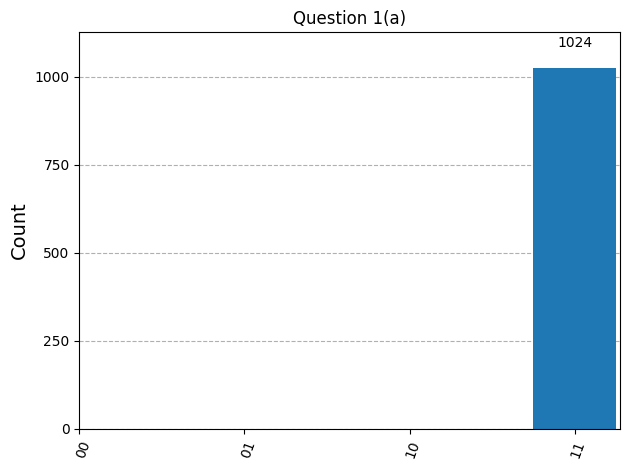

In [3]:
figure = plot_histogram(counts_q1a, title="Question 1(a)")

display(figure)
plt.close(figure)

Actual simulator counts: 00: 0; 01: 0; 10: 0; 11: 1024. All 1024 shots give 11, matching P(11) = 1 and probability 0 for the other outcomes.

## Question 1(b)

### 4×4 Operator Using the Kronecker Product Formulation

![Question 1(b), handwritten page 1](report_assets/handwritten_q1b/page_1.jpeg)

---

![Question 1(b), handwritten page 2](report_assets/handwritten_q1b/page_2.jpeg)

---

### Action of the Operator on the Kets: |00⟩, |01⟩, |10⟩, |11⟩

![Question 1(b), handwritten page 3](report_assets/handwritten_q1b/page_3.jpeg)

---

### Probability Measurements

![Question 1(b), handwritten page 4](report_assets/handwritten_q1b/page_4.jpeg)

---

Verify the operator and all four basis actions, then compare the predicted probabilities with actual simulator counts.

In [4]:
qc = QuantumCircuit(2)
qc.x(0)
counts_q1b = analyze(qc, np.kron(I2, X), 'Question 1(b)')

Question 1(b): operator and all four basis actions verified against Qiskit.


**State vector at the circuit output:**

<IPython.core.display.Latex object>

| Outcome | Exact probability | Expected count | Observed count |
|---|---:|---:|---:|
| 00 | 0.00 | 0 | 0 |
| 01 | 1.00 | 1024 | 1024 |
| 10 | 0.00 | 0 | 0 |
| 11 | 0.00 | 0 | 0 |

### Qiskit Histograms Verifying the Measurement Predictions

Qiskit measurement snapshot for input |00⟩. The horizontal axis shows q1q0 outcomes; the vertical axis shows counts.

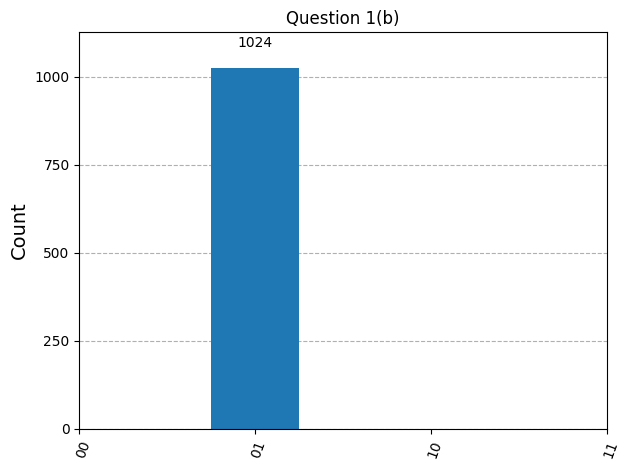

In [5]:
figure = plot_histogram(counts_q1b, title="Question 1(b)")

display(figure)
plt.close(figure)

Actual simulator counts: 00: 0; 01: 1024; 10: 0; 11: 0. All 1024 shots give 01, matching P(01) = 1 and probability 0 for the other outcomes.

## Question 1(c)

### 4×4 Operator Using the Kronecker Product Formulation

![Question 1(c), handwritten page 1](report_assets/handwritten_q1c/page_1.jpeg)

---

![Question 1(c), handwritten page 2](report_assets/handwritten_q1c/page_2.jpeg)

For clarity, the bottom-right entry of the lower-right block uses two negative factors:

$$ \left(-\frac{1}{\sqrt{2}}\right)\left(-\frac{1}{\sqrt{2}}\right)=\frac{1}{2}. $$

---

### Action of the Operator on the Kets: |00⟩, |01⟩, |10⟩, |11⟩

![Question 1(c), handwritten page 3](report_assets/handwritten_q1c/page_3.jpeg)

---

![Question 1(c), handwritten page 4](report_assets/handwritten_q1c/page_4.jpeg)

---

### Probability Measurements

![Question 1(c), handwritten page 5](report_assets/handwritten_q1c/page_5.jpeg)

---

Verify the operator and all four basis actions, then compare the predicted probabilities with actual simulator counts.

In [6]:
qc = QuantumCircuit(2)
qc.h(0)
qc.h(1)
counts_q1c = analyze(qc, np.kron(H, H), 'Question 1(c)')

Question 1(c): operator and all four basis actions verified against Qiskit.


**State vector at the circuit output:**

<IPython.core.display.Latex object>

| Outcome | Exact probability | Expected count | Observed count |
|---|---:|---:|---:|
| 00 | 0.25 | 256 | 264 |
| 01 | 0.25 | 256 | 275 |
| 10 | 0.25 | 256 | 252 |
| 11 | 0.25 | 256 | 233 |

### Qiskit Histograms Verifying the Measurement Predictions

Qiskit measurement snapshot for input |00⟩. The horizontal axis shows q1q0 outcomes; the vertical axis shows counts.

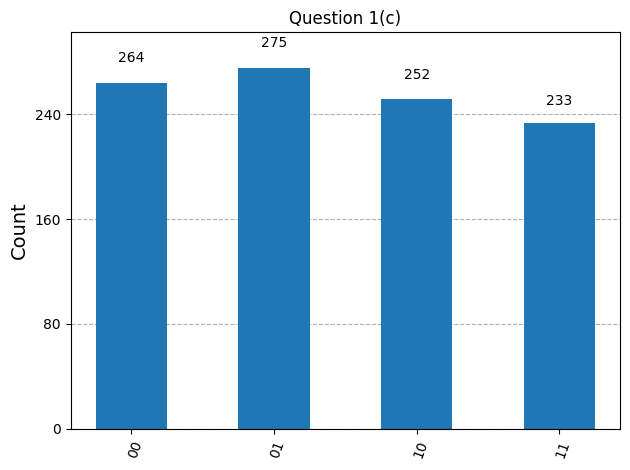

In [7]:
figure = plot_histogram(counts_q1c, title="Question 1(c)")

display(figure)
plt.close(figure)

Actual simulator counts: 00: 264; 01: 275; 10: 252; 11: 233. The prediction is probability 1/4 for every outcome, or 256 counts per outcome on average. The observed bars are approximately equal; their small differences arise from finite-shot sampling in the ideal simulator.

## Question 1(d)

### 4×4 Operator Using the Kronecker Product Formulation

The first gate is Z on q0: I ⊗ Z. The second is Y on q1: Y ⊗ I. Thus U = (Y ⊗ I)(I ⊗ Z) = (YI) ⊗ (IZ) = Y ⊗ Z.

The entries of Y are 0,−i,i,0. They scale the four blocks in that order. In particular, (−i)(−1) = i and i(−1) = −i; retain these signs.

$$ Y = \begin{bmatrix}0 & -i\\i & 0\end{bmatrix}, \qquad Z = \begin{bmatrix}1 & 0\\0 & -1\end{bmatrix}. $$

**Single-qubit actions:**

Multiply the two matrix rows by the input column. These are the only single-qubit actions needed for this part.

**Input $Y|0\rangle$:**

$$ 0\cdot1 + (-i)\cdot0 = 0 $$

$$ i\cdot1 + 0\cdot0 = i $$

Therefore $ Y|0\rangle = i|1\rangle $.

**Input $Y|1\rangle$:**

$$ 0\cdot0 + (-i)\cdot1 = -i $$

$$ i\cdot0 + 0\cdot1 = 0 $$

Therefore $ Y|1\rangle = -i|0\rangle $.

**Input $Z|0\rangle$:**

$$ 1\cdot1 + 0\cdot0 = 1 $$

$$ 0\cdot1 + (-1)\cdot0 = 0 $$

Therefore $ Z|0\rangle = |0\rangle $.

**Input $Z|1\rangle$:**

$$ 1\cdot0 + 0\cdot1 = 0 $$

$$ 0\cdot0 + (-1)\cdot1 = -1 $$

Therefore $ Z|1\rangle = -1|1\rangle $.

**Kronecker product expansion:**

Each entry of the left factor multiplies **every** entry of the right factor.

**Upper-left block:**

$$ (0)Z = \begin{bmatrix}(0)\cdot(1) & (0)\cdot(0)\\(0)\cdot(0) & (0)\cdot(-1)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 0\\0 & 0\end{bmatrix}. $$

**Upper-right block:**

$$ (-i)Z = \begin{bmatrix}(-i)\cdot(1) & (-i)\cdot(0)\\(-i)\cdot(0) & (-i)\cdot(-1)\end{bmatrix} $$

$$ = \begin{bmatrix}-i & 0\\0 & i\end{bmatrix}. $$

**Lower-left block:**

$$ (i)Z = \begin{bmatrix}(i)\cdot(1) & (i)\cdot(0)\\(i)\cdot(0) & (i)\cdot(-1)\end{bmatrix} $$

$$ = \begin{bmatrix}i & 0\\0 & -i\end{bmatrix}. $$

**Lower-right block:**

$$ (0)Z = \begin{bmatrix}(0)\cdot(1) & (0)\cdot(0)\\(0)\cdot(0) & (0)\cdot(-1)\end{bmatrix} $$

$$ = \begin{bmatrix}0 & 0\\0 & 0\end{bmatrix}. $$

Place the upper two blocks side by side, then the lower two blocks:

$$ U = Y \otimes Z = \begin{bmatrix}0 & 0 & -i & 0\\0 & 0 & 0 & i\\i & 0 & 0 & 0\\0 & -i & 0 & 0\end{bmatrix}. $$

### Action of the Operator on the Kets: |00⟩, |01⟩, |10⟩, |11⟩

Use the single-qubit actions above. Multiply any scalar phases and distribute tensor products before combining the two bits.

**Input $|00\rangle$:**

$$ U|00\rangle = (Y|0\rangle) \otimes (Z|0\rangle) $$

$$  = (i|1\rangle) \otimes (1|0\rangle) $$

$$  = (i)(1)|10\rangle $$

$$  = i|10\rangle $$

**Input $|01\rangle$:**

$$ U|01\rangle = (Y|0\rangle) \otimes (Z|1\rangle) $$

$$  = (i|1\rangle) \otimes (-1|1\rangle) $$

$$  = (i)(-1)|11\rangle $$

$$  = -i|11\rangle $$

**Input $|10\rangle$:**

$$ U|10\rangle = (Y|1\rangle) \otimes (Z|0\rangle) $$

$$  = (-i|0\rangle) \otimes (1|0\rangle) $$

$$  = (-i)(1)|00\rangle $$

$$  = -i|00\rangle $$

**Input $|11\rangle$:**

$$ U|11\rangle = (Y|1\rangle) \otimes (Z|1\rangle) $$

$$  = (-i|0\rangle) \otimes (-1|1\rangle) $$

$$  = (-i)(-1)|01\rangle $$

$$  = i|01\rangle $$

### Probability Measurements

The initialized input is $|00\rangle=(1,0,0,0)^T$. Keep all four row products visible:

$$ U|00\rangle = \begin{bmatrix}0 & 0 & -i & 0\\0 & 0 & 0 & i\\i & 0 & 0 & 0\\0 & -i & 0 & 0\end{bmatrix}\begin{bmatrix}1\\0\\0\\0\end{bmatrix}. $$

**Row 1:** $ 0\cdot1 + 0\cdot0 + (-i)\cdot0 + 0\cdot0 = 0 $.

**Row 2:** $ 0\cdot1 + 0\cdot0 + 0\cdot0 + i\cdot0 = 0 $.

**Row 3:** $ i\cdot1 + 0\cdot0 + 0\cdot0 + 0\cdot0 = i $.

**Row 4:** $ 0\cdot1 + (-i)\cdot0 + 0\cdot0 + 0\cdot0 = 0 $.

$$ |\psi_f\rangle = \begin{bmatrix}0\\0\\i\\0\end{bmatrix} = i|10\rangle. $$

**Probability measurements and normalization:**

Take the squared magnitude of each output amplitude, rather than the amplitude itself:

$P(00) = |0|^2 = 0\cdot0 = 0$.

$P(01) = |0|^2 = 0\cdot0 = 0$.

$P(10) = |i|^2 = (-i)i = -i^2 = -(-1) = 1$.

$P(11) = |0|^2 = 0\cdot0 = 0$.

$$ 0 + 0 + 1 + 0 = 1. $$

For the other basis inputs above, there is exactly one nonzero coefficient, of magnitude 1. Its output ket has probability 1 and the other three outcomes have probability 0.

Verify the operator and all four basis actions, then compare the predicted probabilities with actual simulator counts.

In [8]:
qc = QuantumCircuit(2)
qc.z(0)
qc.y(1)
counts_q1d = analyze(qc, np.kron(Y, Z), 'Question 1(d)')

Question 1(d): operator and all four basis actions verified against Qiskit.


**State vector at the circuit output:**

<IPython.core.display.Latex object>

| Outcome | Exact probability | Expected count | Observed count |
|---|---:|---:|---:|
| 00 | 0.00 | 0 | 0 |
| 01 | 0.00 | 0 | 0 |
| 10 | 1.00 | 1024 | 1024 |
| 11 | 0.00 | 0 | 0 |

### Qiskit Histograms Verifying the Measurement Predictions

Qiskit measurement snapshot for input |00⟩. The horizontal axis shows q1q0 outcomes; the vertical axis shows counts.

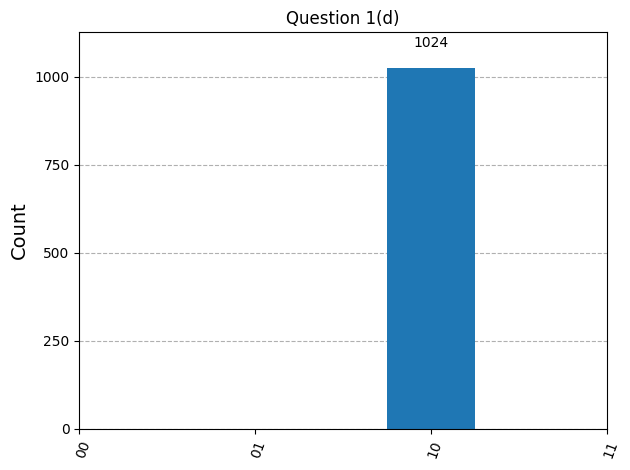

In [9]:
figure = plot_histogram(counts_q1d, title="Question 1(d)")

display(figure)
plt.close(figure)

Actual simulator counts: 00: 0; 01: 0; 10: 1024; 11: 0. All 1024 shots give 10, matching P(10) = 1 and probability 0 for the other outcomes. The global phase i in i|10⟩ does not change measurement probabilities.

## Question 2: Output State Vector

![Question 2, handwritten page 1](report_assets/handwritten_q2/page_1.jpeg)

---

![Question 2, handwritten page 2](report_assets/handwritten_q2/page_2.jpeg)

---

Verify the state before measurement and display the circuit with the measurement gates shown in the assignment.

<IPython.core.display.Latex object>

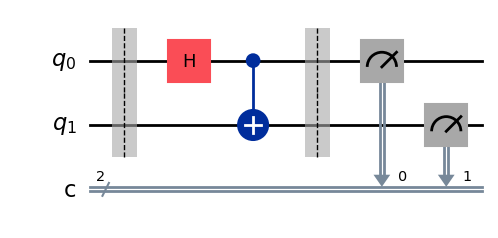

In [10]:
qc2 = QuantumCircuit(2, 2)
qc2.barrier()
qc2.h(0)
qc2.cx(0, 1)
qc2.barrier()
psi_out = Statevector.from_label("00").evolve(qc2)
assert np.allclose(psi_out.data, np.array([1, 0, 0, 1]) / np.sqrt(2))
display(array_to_latex(psi_out.data.reshape(-1, 1), prefix=r"|\psi_{out}\rangle = "))
qc2.measure([0, 1], [0, 1])
figure = qc2.draw("mpl")
display(figure)
plt.close(figure)

## Question 3: Representation of Qubits on an IBM Quantum Computer

IBM implements physical qubits using superconducting *transmon* circuits, which contain a Josephson junction connected in parallel with a capacitor (IBM, n.d.). The junction makes the circuit an anharmonic oscillator: successive energy levels have different spacings, allowing a microwave drive to address the qubit transition selectively (Koch et al., 2007). The ground and first excited energy states represent |0⟩ and |1⟩. Within this two-state computational subspace, a pure qubit state is |ψ⟩ = α|0⟩ + β|1⟩, where the complex amplitudes satisfy |α|² + |β|² = 1; their magnitudes and relative phase specify the state (Krantz et al., 2019).

The processor operates inside a dilution refrigerator at millikelvin temperatures to support superconductivity and reduce thermal excitation (Krantz et al., 2019). Calibrated microwave pulses control the qubit state and implement gates (IBM, n.d.). Measurement uses a coupled microwave resonator whose response depends on the qubit state; the amplified signal is classified as a classical 0 or 1 (Krantz et al., 2019). Ideally, measuring α|0⟩ + β|1⟩ produces 0 with probability |α|² and 1 with probability |β|². Repeated preparations estimate these probabilities; a single measurement does not reveal both complex amplitudes (Krantz et al., 2019).

### References

IBM. (n.d.). *Running quantum circuits*. IBM Quantum Learning. [https://quantum.cloud.ibm.com/learning/en/courses/quantum-computing-in-practice/running-quantum-circuits](https://quantum.cloud.ibm.com/learning/en/courses/quantum-computing-in-practice/running-quantum-circuits)

Koch, J., Yu, T. M., Gambetta, J., Houck, A. A., Schuster, D. I., Majer, J., Blais, A., Devoret, M. H., Girvin, S. M., & Schoelkopf, R. J. (2007). Charge-insensitive qubit design derived from the Cooper pair box. *Physical Review A, 76*(4), Article 042319. [https://doi.org/10.1103/PhysRevA.76.042319](https://doi.org/10.1103/PhysRevA.76.042319)

Krantz, P., Kjaergaard, M., Yan, F., Orlando, T. P., Gustavsson, S., & Oliver, W. D. (2019). A quantum engineer's guide to superconducting qubits. *Applied Physics Reviews, 6*(2), Article 021318. [https://doi.org/10.1063/1.5089550](https://doi.org/10.1063/1.5089550)